# 로지스틱 회귀: 은행 정기예금 가입 예측

포르투갈 은행 전화 마케팅 자료로 정기예금 가입 여부(y)를 예측합니다. 데이터 확인부터 전처리, 학습, 평가와 계수 해석까지 순서대로 실습합니다.

**학습 목표**
- 이진 분류에 로지스틱 회귀 적용
- 수치형·범주형 변수 전처리
- 불균형 데이터 평가 지표 이해
- 10-fold 교차검증으로 하이퍼파라미터를 선택하고 테스트 데이터로 최종 평가

> 교육용 실습이며 실제 고객 마케팅에 사용할 모델이 아닙니다.

## 1. 준비: 라이브러리와 데이터 불러오기

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트 설정 (venv에 설치되어 있음)
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay, accuracy_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/bank-full.csv", sep=";")
print(f"데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열")
df.head()


데이터 크기: 45,211행 × 17열


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. 데이터 살펴보기

예측 대상 y의 자료형, 결측값, 가입 여부 분포를 확인합니다. 가입 비율이 낮으므로 정확도 외 지표도 살펴봅니다.

,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
missing values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,count,share
y,,
no,39922,88.3%
yes,5289,11.7%


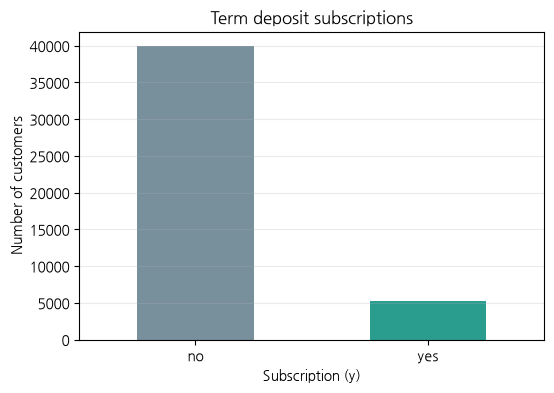

In [2]:
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().rename("missing values").to_frame().T)
target_counts = df["y"].value_counts()
target_rate = df["y"].value_counts(normalize=True)
display(pd.DataFrame({"count": target_counts, "share": target_rate.map(lambda x: f"{x:.1%}")}))
ax = target_counts.reindex(["no", "yes"]).plot(kind="bar", color=["#78909c", "#2a9d8f"], rot=0, figsize=(6, 4))
ax.set(title="Term deposit subscriptions", xlabel="Subscription (y)", ylabel="Number of customers")
ax.grid(axis="y", alpha=0.25)
plt.show()


## 3. 예측 변수와 데이터

duration은 마지막 통화가 끝난 뒤에야 알 수 있습니다. 캠페인 전 예측에서는 사용할 수 없어 모델에서 제외합니다. 포함하면 평가 점수가 과도하게 좋아질 수 있습니다. 데이터 분할에는 가입 비율 유지와 고정 난수 시드를 적용합니다.

In [3]:
target = (df["y"] == "yes").astype(int)
features = df.drop(columns=["y", "duration"])

numeric_features = features.select_dtypes(include="number").columns.tolist()
categorical_features = features.select_dtypes(exclude="number").columns.tolist()
print("수치형 변수:", numeric_features)
print("범주형 변수:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42, stratify=target
)
print(f"학습 데이터: {len(X_train):,}행 | 테스트 데이터: {len(X_test):,}행")
print(f"학습 세트 가입률: {y_train.mean():.1%} | 테스트 세트 가입률: {y_test.mean():.1%}")


수치형 변수: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
범주형 변수: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
학습 데이터: 36,168행 | 테스트 데이터: 9,043행
학습 세트 가입률: 11.7% | 테스트 세트 가입률: 11.7%


## 4. 전처리와 모델 학습

범주형 변수는 원-핫 인코딩하고 수치형 변수는 표준화합니다. Pipeline으로 전처리 기준이 학습 데이터에서만 계산되도록 합니다. balanced class weight는 가입 고객이 소수인 점을 보정합니다.

In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
print("Preprocessor is ready.")


Preprocessor is ready.


In [5]:
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("logistic", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model.fit(X_train, y_train)
print("모델 학습이 완료되었습니다.")


모델 학습이 완료되었습니다.


## 5. 10-fold 교차검증으로 하이퍼파라미터 튜닝

학습 데이터만 10개 fold로 나누고, 9개로 학습하고 1개로 검증하는 과정을 10번 반복합니다. 가입 비율을 유지하는 `StratifiedKFold`를 사용합니다.

- `C`: 규제 강도의 역수입니다. 작을수록 규제가 강해집니다.
- `class_weight`: 기본 가중치와 소수 클래스에 가중치를 주는 `"balanced"`를 비교합니다.
- 선택 기준: 10개 검증 fold의 평균 ROC-AUC. 불균형 데이터에 참고할 Average Precision(AP)도 함께 기록합니다.

`GridSearchCV`에 전처리를 포함한 Pipeline을 전달하므로 각 fold의 학습 부분에서만 인코딩·표준화 기준을 학습합니다. 테스트 데이터는 튜닝에 사용하지 않습니다. 8개 조합 × 10개 fold로 80번 검증하고, 최적 조합을 전체 학습 데이터에 다시 적합합니다.

> 이 실습은 무작위 분할을 가정합니다. 미래 캠페인을 예측하는 운영 평가에는 시간 순서를 고려한 분할도 필요합니다.

In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {
    "logistic__C": [0.01, 0.1, 1.0, 10.0],
    "logistic__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
    refit="roc_auc",
    cv=cv,
    n_jobs=1,
    error_score="raise",
)
grid_search.fit(X_train, y_train)
print("10-fold 교차검증과 최적 모델의 재학습이 완료되었습니다.")


10-fold 교차검증과 최적 모델의 재학습이 완료되었습니다.


### 교차검증 결과 비교

평균 검증 ROC-AUC가 높은 순서로 조합을 비교합니다. 표준편차는 10개 fold 사이의 점수 변동이며 신뢰구간이 아닙니다. 여러 조합 중 가장 높은 점수를 선택했으므로 이 교차검증 점수만으로 최종 일반화 성능을 단정하지 않습니다.

In [7]:
cv_results = pd.DataFrame(grid_search.cv_results_)
result_columns = [
    "param_logistic__C",
    "param_logistic__class_weight",
    "mean_test_roc_auc",
    "std_test_roc_auc",
    "mean_test_average_precision",
    "rank_test_roc_auc",
]
cv_summary = cv_results[result_columns].sort_values("rank_test_roc_auc")
display(cv_summary.reset_index(drop=True).round(4))
print("최적 하이퍼파라미터:", grid_search.best_params_)
print(f"최적 조합의 평균 검증 ROC-AUC: {grid_search.best_score_:.4f}")


,param_logistic__C,param_logistic__class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_average_precision,rank_test_roc_auc
0,0.10,balanced,0.7646,0.0073,0.4006,1
1,0.01,balanced,0.7645,0.0069,0.3995,2
2,1.00,balanced,0.7644,0.0073,0.4000,3
3,10.00,balanced,0.7643,0.0073,0.4003,4
4,0.10,NaN,0.7638,0.0080,0.4043,5
5,1.00,NaN,0.7634,0.0083,0.4039,6
6,10.00,NaN,0.7633,0.0083,0.4039,7
7,0.01,NaN,0.7617,0.0072,0.4006,8


최적 하이퍼파라미터: {'logistic__C': 0.1, 'logistic__class_weight': 'balanced'}
최적 조합의 평균 검증 ROC-AUC: 0.7646


### 선택된 모델로 최종 테스트 평가

`best_estimator_`는 최적 조합으로 전체 학습 데이터에 다시 적합된 Pipeline입니다. 아래의 예측·성능 평가·계수 해석은 이 모델을 사용합니다. 테스트 점수를 보고 하이퍼파라미터를 다시 선택하면 테스트 데이터도 튜닝에 사용한 셈이 됩니다.

In [8]:
model = grid_search.best_estimator_
print("이후 평가는 교차검증으로 선택한 모델을 사용합니다.")


이후 평가는 교차검증으로 선택한 모델을 사용합니다.


## 6. 성능 평가

정확도, 정밀도, 재현율, ROC-AUC와 혼동 행렬을 확인합니다. 정밀도는 가입 예측 중 실제 가입 비율, 재현율은 실제 가입자 중 찾아낸 비율입니다.

In [9]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print(f"정확도: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_probability):.3f}")
print("\n분류 보고서 (임계값=0.5)")
print(classification_report(y_test, y_pred, target_names=["미가입(no)", "가입(yes)"], zero_division=0))


정확도: 0.754
ROC-AUC: 0.772

분류 보고서 (임계값=0.5)
              precision    recall  f1-score   support

     미가입(no)       0.94      0.77      0.85      7985
     가입(yes)       0.27      0.64      0.38      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043



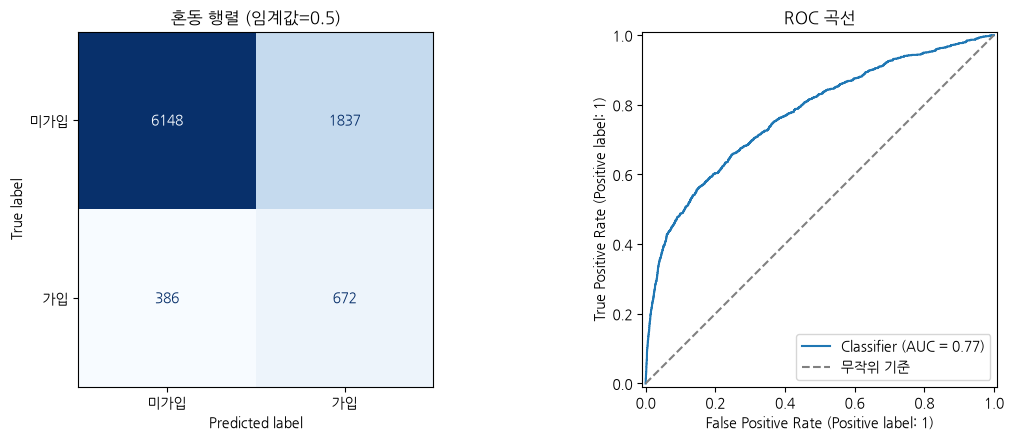

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["미가입", "가입"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("혼동 행렬 (임계값=0.5)")
RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="무작위 기준")
axes[1].set_title("ROC 곡선")
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. 분류 임계값 비교

임계값을 낮추면 재현율이 커질 수 있지만 미가입자를 잘못 분류하는 수도 늘 수 있습니다. 운영 임계값은 검증 데이터와 사용 목적에 맞춰 정해야 합니다.

In [11]:
from sklearn.metrics import precision_score, recall_score

threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    prediction = (y_probability >= threshold).astype(int)
    threshold_rows.append({
        "임계값": threshold,
        "정밀도": precision_score(y_test, prediction, zero_division=0),
        "재현율": recall_score(y_test, prediction, zero_division=0),
        "가입으로 분류한 고객 수": int(prediction.sum()),
    })
pd.DataFrame(threshold_rows).set_index("임계값").style.format({"정밀도": "{:.3f}", "재현율": "{:.3f}"})


,정밀도,재현율,가입으로 분류한 고객 수
임계값,,,
0.300000,0.150,0.918,6459
0.500000,0.268,0.635,2509
0.700000,0.518,0.375,767


## 8. 계수 해석

계수 부호는 다른 변수가 같을 때 가입 로그 오즈의 방향을 나타냅니다. 범주형 계수는 생략된 기준 범주와 비교합니다. 계수는 인과 효과가 아닙니다.

In [12]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["logistic"].coef_[0]
coef_table = pd.DataFrame({"변수": feature_names, "계수": coefficients})
coef_table["절댓값"] = coef_table["계수"].abs()
display(coef_table.sort_values("절댓값", ascending=False).head(15).drop(columns="절댓값").style.format({"계수": "{:.3f}"}))


,변수,계수
48,categorical__poutcome_success,1.622
41,categorical__month_mar,1.128
38,categorical__month_jan,-0.983
44,categorical__month_oct,0.909
43,categorical__month_nov,-0.751
45,categorical__month_sep,0.750
36,categorical__month_dec,0.737
35,categorical__month_aug,-0.709
33,categorical__contact_unknown,-0.705
46,categorical__poutcome_failure,-0.650


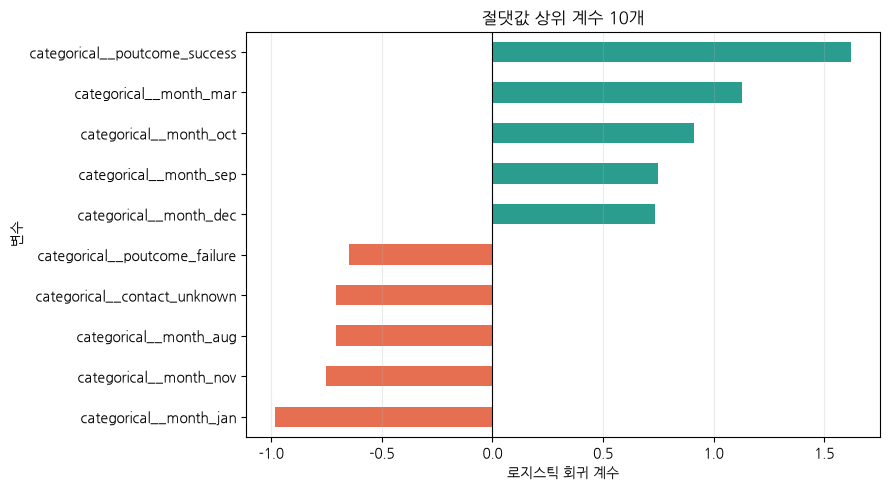

In [13]:
top_coefficients = coef_table.nlargest(10, "절댓값").sort_values("계수")
colors = ["#e76f51" if value < 0 else "#2a9d8f" for value in top_coefficients["계수"]]
ax = top_coefficients.plot.barh(x="변수", y="계수", color=colors, legend=False, figsize=(9, 5))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="절댓값 상위 계수 10개", xlabel="로지스틱 회귀 계수", ylabel="변수")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 9. 검토


### 클래스 가중치를 끄면 재현율이 어떻게 달라질까?

선택된 모델과 같은 `C`를 쓰고 `class_weight`만 `"balanced"`와 `None`으로 바꾸어 각각 학습 데이터 전체에 다시 학습합니다. 임계값 0.5에서 가입 클래스의 재현율·정밀도와 함께, 임계값과 무관한 순위 지표(ROC-AUC, AP)도 비교합니다. 이 비교는 결과를 이해하기 위한 것이며, 테스트 점수를 보고 모델을 다시 고르지는 않습니다.

In [14]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, average_precision_score

# 선택된 C는 그대로 두고 class_weight만 바꾼 두 모델을 학습 데이터로 다시 학습
weight_rows = []
for class_weight in ["balanced", None]:
    candidate = clone(model).set_params(logistic__class_weight=class_weight)
    candidate.fit(X_train, y_train)

    probability = candidate.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    weight_rows.append({
        "class_weight": str(class_weight),
        "가입 재현율": recall_score(y_test, prediction),
        "가입 정밀도": precision_score(y_test, prediction, zero_division=0),
        "가입으로 분류한 고객 수": int(prediction.sum()),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "AP": average_precision_score(y_test, probability),
    })

print(f"C = {model.named_steps['logistic'].C} | 테스트 세트 실제 가입자 수: {int(y_test.sum()):,}명 (임계값=0.5)")
pd.DataFrame(weight_rows).set_index("class_weight").style.format(
    {"가입 재현율": "{:.3f}", "가입 정밀도": "{:.3f}", "ROC-AUC": "{:.3f}", "AP": "{:.3f}"}
)

C = 0.1 | 테스트 세트 실제 가입자 수: 1,058명 (임계값=0.5)


,가입 재현율,가입 정밀도,가입으로 분류한 고객 수,ROC-AUC,AP
class_weight,,,,,
balanced,0.635,0.268,2509,0.772,0.409
None,0.171,0.673,269,0.773,0.411


- 재현율: 가중치를 끄면 실제 가입자 1,058명 중 찾아내는 비율이 63.5%에서 17.1%로 크게 떨어집니다.
- 정밀도: 대신 정밀도는 0.27에서 0.67로 오릅니다. 가입으로 분류하는 고객 수 자체가 2,509명에서 269명으로 줄기 때문입니다.
- 순위 지표: ROC-AUC와 AP는 두 모델이 거의 같습니다. 가중치는 고객의 순위를 거의 바꾸지 않고, 예측 확률을 전반적으로 올려 임계값 0.5에서의 판정을 바꾸는 효과가 큽니다. 그래서 가중치를 끈 모델도 임계값을 낮추면 비슷한 재현율을 얻을 수 있습니다. 


### 임계값에 따른 정밀도와 재현율

예측 확률이 임계값 이상이면 가입으로 분류합니다. 임계값을 0.05부터 0.95까지 바꾸면서 가입 클래스의 정밀도와 재현율이 어떻게 맞바뀌는지 확인합니다. 연습 문제 1과 이어서 `class_weight="balanced"` 모델과 `None` 모델을 함께 비교합니다.

> 여기서는 비교를 위해 테스트 데이터를 사용합니다. 실제로 운영 임계값을 정할 때는 학습 데이터 안의 검증 데이터로 정해야 합니다.

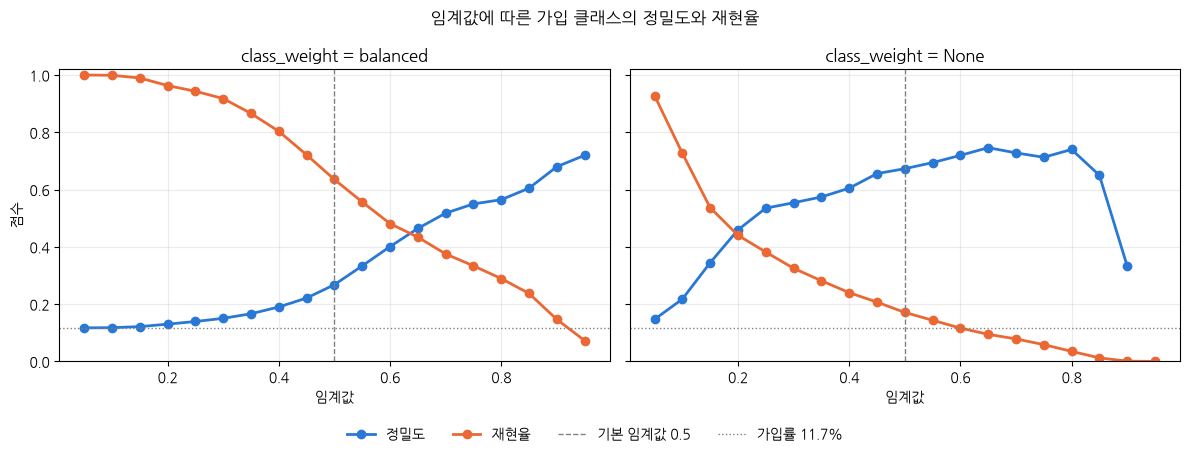

In [15]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

# 1. 두 모델의 테스트 예측 확률 구하기 (C는 선택된 값, class_weight만 다름)
probabilities = {}
for class_weight in ["balanced", None]:
    candidate = clone(model).set_params(logistic__class_weight=class_weight)
    candidate.fit(X_train, y_train)
    probabilities[str(class_weight)] = candidate.predict_proba(X_test)[:, 1]

# 2. 임계값마다 정밀도, 재현율, 가입으로 분류한 고객 수 계산
sweep_rows = []
for name, probability in probabilities.items():
    for threshold in thresholds:
        prediction = (probability >= threshold).astype(int)
        sweep_rows.append({
            "class_weight": name,
            "임계값": threshold,
            # 가입으로 분류한 고객이 없으면 정밀도를 정의할 수 없으므로 NaN으로 둠
            "정밀도": precision_score(y_test, prediction, zero_division=np.nan),
            "재현율": recall_score(y_test, prediction, zero_division=0),
            "가입으로 분류한 고객 수": int(prediction.sum()),
        })
sweep = pd.DataFrame(sweep_rows)

# 3. 모델별로 임계값에 따른 정밀도·재현율 그래프
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, probabilities):
    data = sweep[sweep["class_weight"] == name]
    ax.plot(data["임계값"], data["정밀도"], marker="o", linewidth=2, color="#2a78d6", label="정밀도")
    ax.plot(data["임계값"], data["재현율"], marker="o", linewidth=2, color="#eb6834", label="재현율")
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="기본 임계값 0.5")
    ax.axhline(y_test.mean(), color="gray", linestyle=":", linewidth=1, label=f"가입률 {y_test.mean():.1%}")
    ax.set(title=f"class_weight = {name}", xlabel="임계값", ylim=(0, 1.02))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("점수")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.suptitle("임계값에 따른 가입 클래스의 정밀도와 재현율")
plt.tight_layout(rect=(0, 0.07, 1, 1))  # 아래쪽 범례 자리 확보
plt.show()

# 4. 0.1 간격 임계값에서 두 모델을 표로 비교
table = sweep[np.isclose(sweep["임계값"] * 10 % 1, 0)].pivot(
    index="임계값", columns="class_weight", values=["정밀도", "재현율", "가입으로 분류한 고객 수"]
)
table = table.reindex(columns=["balanced", "None"], level="class_weight")
table["가입으로 분류한 고객 수"] = table["가입으로 분류한 고객 수"].astype(int)
table.style.format("{:.3f}", subset=["정밀도", "재현율"], na_rep="-")